<a href="https://colab.research.google.com/github/adityakumarsinghcs24-ship-it/BIO_INSPIRED/blob/main/GreyWolfOptimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Optimal control variables: [0.99979457 1.00147464 0.99973171 0.71398355]
Minimum objective value: 5.065501531187906


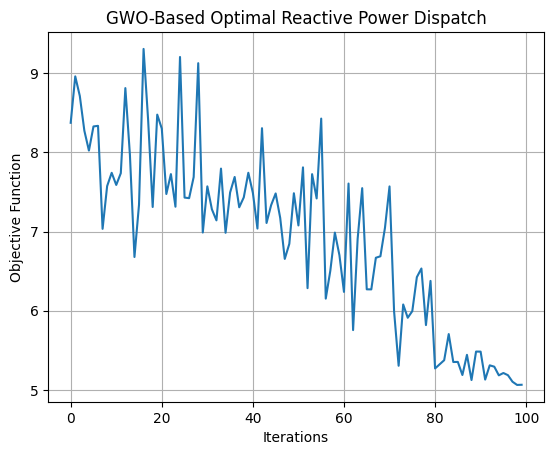

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# GWO parameters
wolves = 20
iterations = 100
dimensions = 4

# Control variable limits (illustrative)
lower = np.array([0.90, 0.90, 0.90, 0.0])
upper = np.array([1.10, 1.10, 1.10, 1.0])

# Illustrative ORPD objective function
def objective(x):
    power_loss = 5 + np.sum((x[:3] - 1.0)**2) * 100
    voltage_deviation = np.sum(np.abs(x[:3] - 1.0))
    wind_penalty = (x[3] - 0.5)**2

    return power_loss + 10 * voltage_deviation + wind_penalty

# Initialize wolves
X = np.random.uniform(lower, upper,
                      (wolves, dimensions))

fitness = np.array([objective(x) for x in X])

best_curve = []

# Grey Wolf Optimization
for t in range(iterations):

    order = np.argsort(fitness)

    alpha = X[order[0]].copy()
    beta = X[order[1]].copy()
    delta = X[order[2]].copy()

    a = 2 - 2 * t / iterations

    for i in range(wolves):

        A1 = 2*a*np.random.rand(dimensions) - a
        C1 = 2*np.random.rand(dimensions)
        D1 = abs(C1*alpha - X[i])
        X1 = alpha - A1*D1

        A2 = 2*a*np.random.rand(dimensions) - a
        C2 = 2*np.random.rand(dimensions)
        D2 = abs(C2*beta - X[i])
        X2 = beta - A2*D2

        A3 = 2*a*np.random.rand(dimensions) - a
        C3 = 2*np.random.rand(dimensions)
        D3 = abs(C3*delta - X[i])
        X3 = delta - A3*D3

        X[i] = (X1 + X2 + X3) / 3

        X[i] = np.clip(X[i], lower, upper)

        fitness[i] = objective(X[i])

    best_curve.append(np.min(fitness))

# Results
best = np.argmin(fitness)

print("Optimal control variables:", X[best])
print("Minimum objective value:", fitness[best])

# Convergence graph
plt.plot(best_curve)
plt.xlabel("Iterations")
plt.ylabel("Objective Function")
plt.title("GWO-Based Optimal Reactive Power Dispatch")
plt.grid()
plt.show()
